# Environmental data for MARIDA patches: a walkthrough

This notebook shows, for two example MARIDA_5Class patches (one with **marine debris**, one with **algae/Sargassum**):

1. the Sentinel-2 image, the label mask and all 11 spectral bands
2. the spectral indices and per-class spectral signatures used by the pixel classifiers
3. **every environmental feature** attached to the patch, together with the raw gridded fields it was derived from

All environmental values are **real downloaded data**; nothing is synthesised.

| Group | Product | Native resolution | Temporal | Access |
|---|---|---|---|---|
| Sea surface temperature + fronts | GHRSST MUR L4 v4.1 (`jplMURSST41`) | 0.01° ≈ 1.1 km | daily | NOAA ERDDAP |
| Chlorophyll-a | MODIS-Aqua L3 (`erdMH1chla8day`, monthly fallback) | 0.042° ≈ 4.6 km | 8-day / monthly | NOAA ERDDAP |
| Wind, pressure, precipitation | ERA5 single levels | 0.25° ≈ 28 km | hourly | Copernicus CDS |
| Waves, Stokes drift | ERA5 ocean-wave model | 0.5° ≈ 55 km | hourly | Copernicus CDS |

A MARIDA patch is **256 × 256 px at 10 m = 2.56 km × 2.56 km**. MUR SST is the only gap-free daily ocean product close to that scale. Wind, wave and rain data at patch scale don't exist for 2015–2021, so ERA5 is interpolated to the patch centre and to the Sentinel-2 overpass time.

Only MARIDA can be used: MADOS tiles carry no coordinates or dates.

The data are produced by the scripts in `scripts/environmental/` (see the README there).

In [ ]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
import tifffile
from IPython.display import display, Markdown

# Repo root = two levels above notebooks/environmental/
REPO = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if not os.path.exists(os.path.join(REPO, "src")):
    REPO = os.path.abspath(os.getcwd())          # fallback: started from repo root
sys.path.insert(0, REPO)

from src.environmental import era5, erddap, interp
from src.environmental.features import FEATURE_GROUPS, RAW_DIR
from src.features.pixel_features import extract_pixel_features, FEATURE_NAMES

MARIDA = os.path.join(REPO, "data", "MARIDA_5Class")
ENV = pd.read_csv(os.path.join(REPO, "data", "environmental", "marida_env_features.csv")).set_index("patch_id")

EXAMPLES = {
    "Marine Debris":   "4-9-16_16PCC_20",
    "Algae/Sargassum": "19-9-18_16PCC_33",
}

CLASS_NAMES  = ["Background/Unannotated", "Water", "Marine Debris", "Algae/Sargassum", "Other"]
CLASS_COLORS = ["#d9d9d9", "#1f78b4", "#e31a1c", "#33a02c", "#ff7f00"]
BANDS = [("B1", 443, 60), ("B2", 490, 10), ("B3", 560, 10), ("B4", 665, 10), ("B5", 705, 20),
         ("B6", 740, 20), ("B7", 783, 20), ("B8", 842, 10), ("B8A", 865, 20), ("B11", 1610, 20),
         ("B12", 2190, 20)]
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10})
print(f"{len(ENV)} patches with environmental features; examples: {list(EXAMPLES.values())}")

1381 patches with environmental features; examples: ['4-9-16_16PCC_20', '19-9-18_16PCC_33']


In [2]:
def load_patch(pid):
    scene = pid.rsplit("_", 1)[0]
    d = os.path.join(MARIDA, "patches", f"S2_{scene}")
    img = tifffile.imread(os.path.join(d, f"S2_{pid}.tif")).astype(np.float32)
    if img.shape[-1] < img.shape[0]:
        img = np.transpose(img, (2, 0, 1))
    img = np.nan_to_num(img)
    mask = tifffile.imread(os.path.join(d, f"S2_{pid}_cl.tif")).astype(int)
    return img, mask

def stretch(rgb, ref=None, lo=1, hi=99.5):
    # Contrast stretch referenced to `ref` pixels (water/background), so bright
    # floating material stands out instead of setting the colour scale.
    out = np.zeros_like(rgb)
    for i in range(rgb.shape[-1]):
        x = rgb[..., i]
        a, b = np.percentile(x[ref] if ref is not None and ref.sum() > 100 else x, [lo, hi])
        out[..., i] = np.clip((x - a) / (b - a + 1e-9), 0, 1)
    return out

def composite(img, r, g, b, mask=None):
    ref = None if mask is None else np.isin(mask, [0, 1])
    return stretch(np.dstack([img[r], img[g], img[b]]), ref)

MASK_CMAP = ListedColormap(CLASS_COLORS)
MASK_NORM = BoundaryNorm(np.arange(-0.5, 5.5), 5)

def class_legend(mask, ax, loc="lower left"):
    handles = [mpatches.Patch(color=CLASS_COLORS[c], label=f"{c}: {CLASS_NAMES[c]} ({(mask == c).sum():,} px)")
               for c in range(5) if (mask == c).any()]
    ax.legend(handles=handles, loc=loc, fontsize=7, framealpha=0.9)

def footprint(ax, r, **kw):
    ax.add_patch(mpatches.Rectangle((r.lon_min, r.lat_min), r.lon_max - r.lon_min, r.lat_max - r.lat_min,
                                    fill=False, **({"ec": "magenta", "lw": 2} | kw)))

def raw_grid(key, scene):
    path = os.path.join(RAW_DIR, key, f"{scene}.csv")
    return erddap.to_grid(pd.read_csv(path)) if os.path.exists(path) else None

## 1. Where the patches are

Each dot is one MARIDA scene (one Sentinel-2 tile on one date), coloured by split. The two example patches are starred.

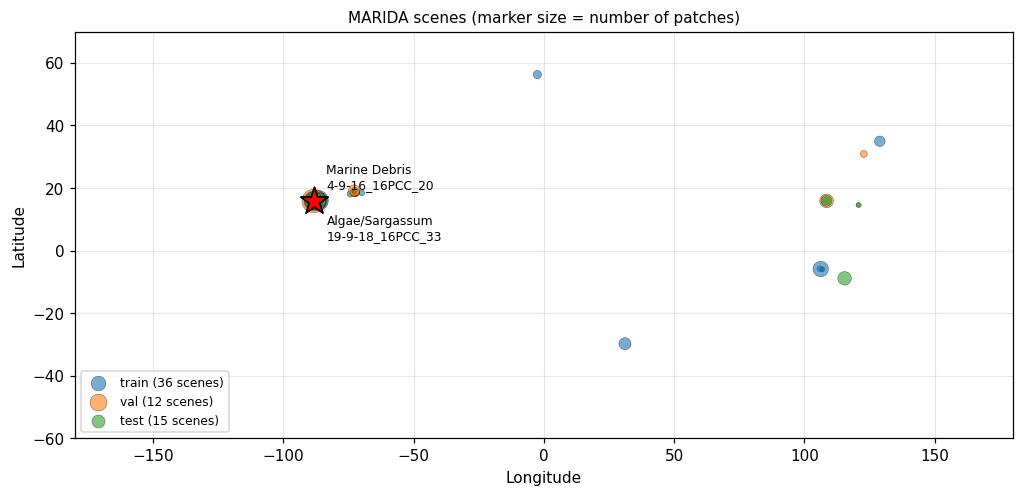

split,test,train,val
scenes,15,36,12


In [3]:
scenes = ENV.groupby("scene").agg(lat=("lat", "mean"), lon=("lon", "mean"), split=("split", "first"),
                                  n=("split", "size"), date=("date", "first"))
fig, ax = plt.subplots(figsize=(11, 4.8))
for split, col in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
    s = scenes[scenes.split == split]
    ax.scatter(s.lon, s.lat, s=s.n * 3, c=col, alpha=0.6, label=f"{split} ({len(s)} scenes)", edgecolor="k", lw=0.3)
for name, pid in EXAMPLES.items():
    r = ENV.loc[pid]
    ax.scatter(r.lon, r.lat, marker="*", s=350, c="red", edgecolor="k", zorder=5)
    ax.annotate(f"{name}\n{pid}", (r.lon, r.lat), xytext=(8, -25 if "Algae" in name else 8),
                textcoords="offset points", fontsize=8)
ax.set_xlim(-180, 180); ax.set_ylim(-60, 70); ax.grid(alpha=0.3)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("MARIDA scenes (marker size = number of patches)")
ax.legend(loc="lower left", fontsize=8)
plt.show()
display(scenes.sort_values("date").groupby("split").size().rename("scenes").to_frame().T)

In [4]:
def show_image(pid):
    img, mask = load_patch(pid)
    r = ENV.loc[pid]
    display(Markdown(f"### Patch `{pid}`: tile **{r.tile}**, acquired **{r.date}** "
                     f"(estimated overpass {r.overpass_utc}), split **{r.split}**  \n"
                     f"Centre {r.lat:.4f}°, {r.lon:.4f}° · EPSG:{int(r.epsg)} · "
                     f"footprint {r.width_m/1000:.2f} km × {r.height_m/1000:.2f} km"))
    fig, ax = plt.subplots(1, 4, figsize=(17, 4.6))
    ax[0].imshow(composite(img, 3, 2, 1, mask)); ax[0].set_title("True colour (B4, B3, B2)")
    ax[1].imshow(composite(img, 7, 3, 2, mask)); ax[1].set_title("False colour (B8, B4, B3)\nfloating material is bright in NIR (stretch referenced to water)")
    ax[2].imshow(mask, cmap=MASK_CMAP, norm=MASK_NORM, interpolation="nearest"); ax[2].set_title("Label mask (5-class)")
    class_legend(mask, ax[2])
    ax[3].imshow(composite(img, 3, 2, 1, mask))
    ov = np.ma.masked_where(mask == 0, mask)
    ax[3].imshow(ov, cmap=MASK_CMAP, norm=MASK_NORM, alpha=0.65, interpolation="nearest")
    ax[3].set_title("Annotations over true colour")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()
    return img, mask

def show_bands(img):
    fig, axes = plt.subplots(2, 6, figsize=(17, 6))
    for i, (name, wl, res) in enumerate(BANDS):
        a = axes.flat[i]
        lo, hi = np.percentile(img[i], [2, 98])
        im = a.imshow(img[i], cmap="gray", vmin=lo, vmax=hi)
        a.set_title(f"{name} · {wl} nm · native {res} m"); a.axis("off")
        plt.colorbar(im, ax=a, fraction=0.046, pad=0.02)
    axes.flat[-1].axis("off")
    plt.suptitle("All 11 Sentinel-2 bands (MARIDA reflectance, all resampled to 10 m)", y=1.0)
    plt.tight_layout(); plt.show()
    stats = pd.DataFrame({
        "band": [b[0] for b in BANDS], "wavelength_nm": [b[1] for b in BANDS], "native_res_m": [b[2] for b in BANDS],
        "min": img.reshape(11, -1).min(1), "mean": img.reshape(11, -1).mean(1),
        "median": np.median(img.reshape(11, -1), 1), "max": img.reshape(11, -1).max(1)}).set_index("band")
    display(stats.style.format({"min": "{:.4f}", "mean": "{:.4f}", "median": "{:.4f}", "max": "{:.4f}"}))

def show_indices(img, mask):
    F = extract_pixel_features(img).reshape(img.shape[1], img.shape[2], -1)
    names = ["NDVI", "NDWI", "FAI", "FDI", "NDMI"]
    fig, ax = plt.subplots(1, 5, figsize=(18, 3.8))
    for a, n in zip(ax, names):
        x = F[..., FEATURE_NAMES.index(n)]
        lo, hi = np.percentile(x, [2, 98])
        im = a.imshow(x, cmap="RdYlGn" if n in ("NDVI", "FAI", "FDI") else "RdBu", vmin=lo, vmax=hi)
        a.contour(np.isin(mask, [2, 3]), levels=[0.5], colors="k", linewidths=0.6)
        a.set_title(n); a.axis("off"); plt.colorbar(im, ax=a, fraction=0.046, pad=0.02)
    plt.suptitle("Spectral indices (black outline = debris/algae annotations)", y=1.02)
    plt.tight_layout(); plt.show()

    # Per-class spectral signature
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    wl = [b[1] for b in BANDS]
    px = img.reshape(11, -1).T; m = mask.ravel()
    for c in range(1, 5):
        if (m == c).sum() == 0: continue
        s = px[m == c]
        ax[0].plot(wl, s.mean(0), "-o", color=CLASS_COLORS[c], label=f"{CLASS_NAMES[c]} (n={len(s):,})")
        ax[0].fill_between(wl, s.mean(0) - s.std(0), s.mean(0) + s.std(0), color=CLASS_COLORS[c], alpha=0.15)
    ax[0].set_xscale("log"); ax[0].set_xticks(wl); ax[0].set_xticklabels([b[0] for b in BANDS], rotation=45)
    ax[0].set_ylabel("Reflectance"); ax[0].set_title("Mean spectral signature per class (±1 std)")
    ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
    Fp = F.reshape(-1, F.shape[-1])
    rows = {CLASS_NAMES[c]: Fp[m == c][:, [FEATURE_NAMES.index(n) for n in names]].mean(0)
            for c in range(1, 5) if (m == c).any()}
    pd.DataFrame(rows, index=names).plot.bar(ax=ax[1], color=[CLASS_COLORS[CLASS_NAMES.index(k)] for k in rows])
    ax[1].set_title("Mean index value per class"); ax[1].grid(alpha=0.3, axis="y"); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()

In [5]:
FEATURE_INFO = {
    "mur_sst_c":               ("Sea surface temperature, patch-footprint mean", "°C", "MUR L4", "0.01° (~1.1 km), daily"),
    "mur_sst_grad_c_per_km":   ("SST gradient magnitude (thermal fronts)", "°C/km", "MUR L4", "0.01°, daily"),
    "modis_log10_chla":        ("log10 chlorophyll-a concentration", "log10 mg/m³", "MODIS-Aqua", "~4.6 km, 8-day/monthly"),
    "era5_u10":                ("10 m eastward wind at overpass", "m/s", "ERA5", "0.25°, hourly"),
    "era5_v10":                ("10 m northward wind at overpass", "m/s", "ERA5", "0.25°, hourly"),
    "era5_wind_speed":         ("10 m wind speed at overpass", "m/s", "ERA5", "0.25°, hourly"),
    "era5_wind_speed_mean_24h":("Mean wind speed, previous 24 h", "m/s", "ERA5", "0.25°, hourly"),
    "era5_wind_speed_mean_72h":("Mean wind speed, previous 72 h", "m/s", "ERA5", "0.25°, hourly"),
    "era5_wind_speed_max_72h": ("Max wind speed, previous 72 h", "m/s", "ERA5", "0.25°, hourly"),
    "era5_u10_mean_72h":       ("Mean eastward wind, previous 72 h", "m/s", "ERA5", "0.25°, hourly"),
    "era5_v10_mean_72h":       ("Mean northward wind, previous 72 h", "m/s", "ERA5", "0.25°, hourly"),
    "era5_msl_hpa":            ("Mean sea-level pressure at overpass", "hPa", "ERA5", "0.25°, hourly"),
    "era5_precip_24h_mm":      ("Total precipitation, previous 24 h", "mm", "ERA5", "0.25°, hourly"),
    "era5_precip_72h_mm":      ("Total precipitation, previous 72 h", "mm", "ERA5", "0.25°, hourly"),
    "era5_precip_7d_mm":       ("Total precipitation, previous 7 days", "mm", "ERA5", "0.25°, hourly"),
    "era5_swh":                ("Significant wave height at overpass", "m", "ERA5 waves", "0.5°, hourly"),
    "era5_swh_mean_72h":       ("Mean significant wave height, previous 72 h", "m", "ERA5 waves", "0.5°, hourly"),
    "era5_stokes_u":           ("Eastward Stokes drift at overpass", "m/s", "ERA5 waves", "0.5°, hourly"),
    "era5_stokes_v":           ("Northward Stokes drift at overpass", "m/s", "ERA5 waves", "0.5°, hourly"),
    "era5_stokes_speed":       ("Stokes drift speed at overpass", "m/s", "ERA5 waves", "0.5°, hourly"),
}
GROUP_OF = {c: g for g, cols in FEATURE_GROUPS.items() for c in cols}

def show_env_table(pid):
    r = ENV.loc[pid]
    rows = []
    for c, (desc, unit, src, res) in FEATURE_INFO.items():
        v = r[c]
        pct = (ENV[c] < v).mean() * 100 if pd.notna(v) else np.nan
        rows.append({"group": GROUP_OF[c], "feature": c, "value": v, "unit": unit, "description": desc,
                     "source": src, "native resolution": res, "percentile in MARIDA": pct})
    df = pd.DataFrame(rows).set_index(["group", "feature"])
    display(Markdown(f"**All environmental features for `{pid}`** "
                     f"(MUR time used: {r.mur_time}; chl-a from **{r.chla_source}** composite dated {r.chla_time})"))
    display(df.style.format({"value": "{:.4g}", "percentile in MARIDA": "{:.0f}"}, na_rep="n/a")
              .bar(subset=["percentile in MARIDA"], vmin=0, vmax=100, color="#9ecae1"))

In [6]:
def show_ocean_fields(pid):
    r = ENV.loc[pid]
    others = ENV[ENV.scene == r.scene]
    sst, c8, cm = raw_grid("mur_sst", r.scene), raw_grid("chla_8day", r.scene), raw_grid("chla_month", r.scene)
    fig, ax = plt.subplots(1, 4, figsize=(19, 4.4))
    v, la, lo, t = sst
    im = ax[0].pcolormesh(lo, la, v, cmap="turbo", shading="nearest"); plt.colorbar(im, ax=ax[0], label="°C")
    ax[0].set_title(f"MUR SST {t[:10]} (0.01° cells)\nwhite = land")
    g = interp.gradient_magnitude(v, la, lo)
    im = ax[1].pcolormesh(lo, la, g, cmap="magma", shading="nearest"); plt.colorbar(im, ax=ax[1], label="°C/km")
    ax[1].set_title("SST gradient magnitude (fronts)")
    for a, grid, name in [(ax[2], c8, "8-day"), (ax[3], cm, "monthly")]:
        if grid is None: a.set_visible(False); continue
        v2, la2, lo2, t2 = grid
        with np.errstate(divide="ignore", invalid="ignore"):
            im = a.pcolormesh(lo2, la2, np.log10(v2), cmap="viridis", shading="nearest")
        plt.colorbar(im, ax=a, label="log10 mg/m³")
        a.set_title(f"MODIS chl-a {name} composite {t2[:10]}\n(~4.6 km cells; white = cloud/land)")
    for a in ax:
        a.scatter(others.lon, others.lat, s=6, c="w", edgecolor="k", lw=0.3, label="other patches of scene")
        footprint(a, r)
        a.set_xlabel("Lon"); a.set_ylabel("Lat"); a.set_aspect(1 / np.cos(np.radians(r.lat)))
    ax[0].legend(fontsize=7, loc="lower left")
    plt.suptitle(f"Ocean fields around {pid} (magenta box = the 2.56 km patch)", y=1.03)
    plt.tight_layout(); plt.show()

def era5_point_series(fields, r):
    return pd.DataFrame({k: pd.Series(interp.sample(f[0], f[2], f[3], r.lat, r.lon, max_km=60.0), index=f[1])
                         for k, f in fields.items()})

def show_era5(pid):
    r = ENV.loc[pid]
    fields = era5.load_scene(os.path.join(RAW_DIR, "era5"), r.scene)
    t = pd.Timestamp(r.overpass_utc).tz_localize(None)

    # Spatial fields at the hour nearest the overpass
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
    u, times, la, lo = fields["u10"]; v = fields["v10"][0]
    k = int(np.argmin(np.abs((times - t).total_seconds())))
    ws = np.hypot(u[k], v[k])
    im = ax[0].pcolormesh(lo, la, ws, cmap="YlGnBu", shading="nearest"); plt.colorbar(im, ax=ax[0], label="m/s")
    ax[0].quiver(*np.meshgrid(lo, la), u[k], v[k], color="k", scale=60)
    ax[0].set_title(f"ERA5 10 m wind {times[k]:%Y-%m-%d %H:%M} UTC (0.25° cells)")
    tp, tt, tla, tlo = fields["tp"]
    win = (tt > t - pd.Timedelta(hours=72)) & (tt <= t)
    im = ax[1].pcolormesh(tlo, tla, tp[win].sum(0) * 1000, cmap="Blues", shading="nearest")
    plt.colorbar(im, ax=ax[1], label="mm"); ax[1].set_title("ERA5 precipitation, 72 h before overpass")
    swh, wt, wla, wlo = fields["swh"]; us, vs = fields["ust"][0], fields["vst"][0]
    kw = int(np.argmin(np.abs((wt - t).total_seconds())))
    im = ax[2].pcolormesh(wlo, wla, swh[kw], cmap="PuBu", shading="nearest"); plt.colorbar(im, ax=ax[2], label="m")
    ax[2].quiver(*np.meshgrid(wlo, wla), us[kw], vs[kw], color="darkred", scale=0.5)
    ax[2].set_title("ERA5 sig. wave height + Stokes drift (0.5° cells)\nwhite = no wave-model sea cell")
    for a in ax:
        a.plot(r.lon, r.lat, "*", ms=16, mfc="magenta", mec="k")
        a.set_xlabel("Lon"); a.set_ylabel("Lat"); a.set_aspect(1 / np.cos(np.radians(r.lat)))
    plt.suptitle(f"ERA5 fields around {pid} (star = patch; patch itself is ~100× smaller than a cell)", y=1.03)
    plt.tight_layout(); plt.show()

    # Time series at the patch centre (what the features are computed from)
    s = era5_point_series(fields, r)
    # CDS returns the year x month x day product, so keep only the contiguous window used for the features
    s = s[(s.index >= t - pd.Timedelta(days=era5.HISTORY_DAYS)) & (s.index <= t + pd.Timedelta(hours=6))]
    s["wind_speed"] = np.hypot(s.u10, s.v10)
    fig, ax = plt.subplots(4, 1, figsize=(15, 10), sharex=True)
    ax[0].plot(s.index, s.wind_speed, label="wind speed"); ax[0].plot(s.index, s.u10, alpha=0.6, label="u10")
    ax[0].plot(s.index, s.v10, alpha=0.6, label="v10"); ax[0].set_ylabel("m/s"); ax[0].legend(fontsize=8, ncol=3)
    ax[1].bar(s.index, s.tp * 1000, width=1 / 24, color="tab:blue"); ax[1].set_ylabel("precip mm/h")
    ax1b = ax[1].twinx(); ax1b.plot(s.index, (s.tp * 1000).cumsum(), color="navy"); ax1b.set_ylabel("cumulative mm")
    ax[2].plot(s.index, s.swh, color="tab:purple", label="sig. wave height (m)")
    ax[2].plot(s.index, np.hypot(s.ust, s.vst) * 10, color="darkred", label="Stokes speed ×10 (m/s)")
    ax[2].legend(fontsize=8)
    ax[3].plot(s.index, s.msl / 100, color="k"); ax[3].set_ylabel("MSLP hPa")
    for a in ax:
        a.axvline(t, color="magenta", lw=2)
        a.axvspan(t - pd.Timedelta(hours=72), t, color="orange", alpha=0.12)
        a.axvspan(t - pd.Timedelta(hours=24), t, color="red", alpha=0.12)
        a.grid(alpha=0.3)
    ax[0].set_xlim(s.index.min(), s.index.max())
    ax[0].set_title(f"ERA5 hourly series at the patch centre, interpolated from the grid\n"
                    f"magenta = S2 overpass {t:%Y-%m-%d %H:%M} UTC · red = 24 h window · orange = 72 h window")
    plt.tight_layout(); plt.show()

In [7]:
def show_resolution(pid):
    r = ENV.loc[pid]
    km_lon = 111.32 * np.cos(np.radians(r.lat))
    cells = [("ERA5 waves 0.5°", 0.5 * km_lon, 0.5 * 111.32, "tab:purple"),
             ("ERA5 atmosphere 0.25°", 0.25 * km_lon, 0.25 * 111.32, "tab:blue"),
             ("MODIS chl-a 0.042°", 0.0417 * km_lon, 0.0417 * 111.32, "tab:green"),
             ("MUR SST 0.01°", 0.01 * km_lon, 0.01 * 111.32, "tab:orange"),
             ("MARIDA patch 2.56 km", 2.56, 2.56, "magenta")]
    fig, ax = plt.subplots(1, 2, figsize=(14, 6))
    for a, lim in [(ax[0], 60), (ax[1], 6)]:
        for name, w, h, col in cells:
            a.add_patch(mpatches.Rectangle((-w / 2, -h / 2), w, h, fill=False, ec=col, lw=2.5, label=f"{name}: {w:.1f} × {h:.1f} km"))
        a.set_xlim(-lim / 2, lim / 2); a.set_ylim(-lim / 2, lim / 2); a.set_aspect("equal")
        a.set_xlabel("km"); a.grid(alpha=0.3)
    ax[0].legend(fontsize=8, loc="upper right"); ax[0].set_title("Grid cell sizes at this latitude")
    ax[1].set_title("Zoomed to the patch")
    plt.tight_layout(); plt.show()

## 2. Example patch: Marine Debris

### Image, mask and spectral bands

### Patch `4-9-16_16PCC_20`: tile **16PCC**, acquired **2016-09-04** (estimated overpass 2016-09-04T16:22:54Z), split **train**  
Centre 15.9682°, -88.2256° · EPSG:32616 · footprint 2.56 km × 2.56 km

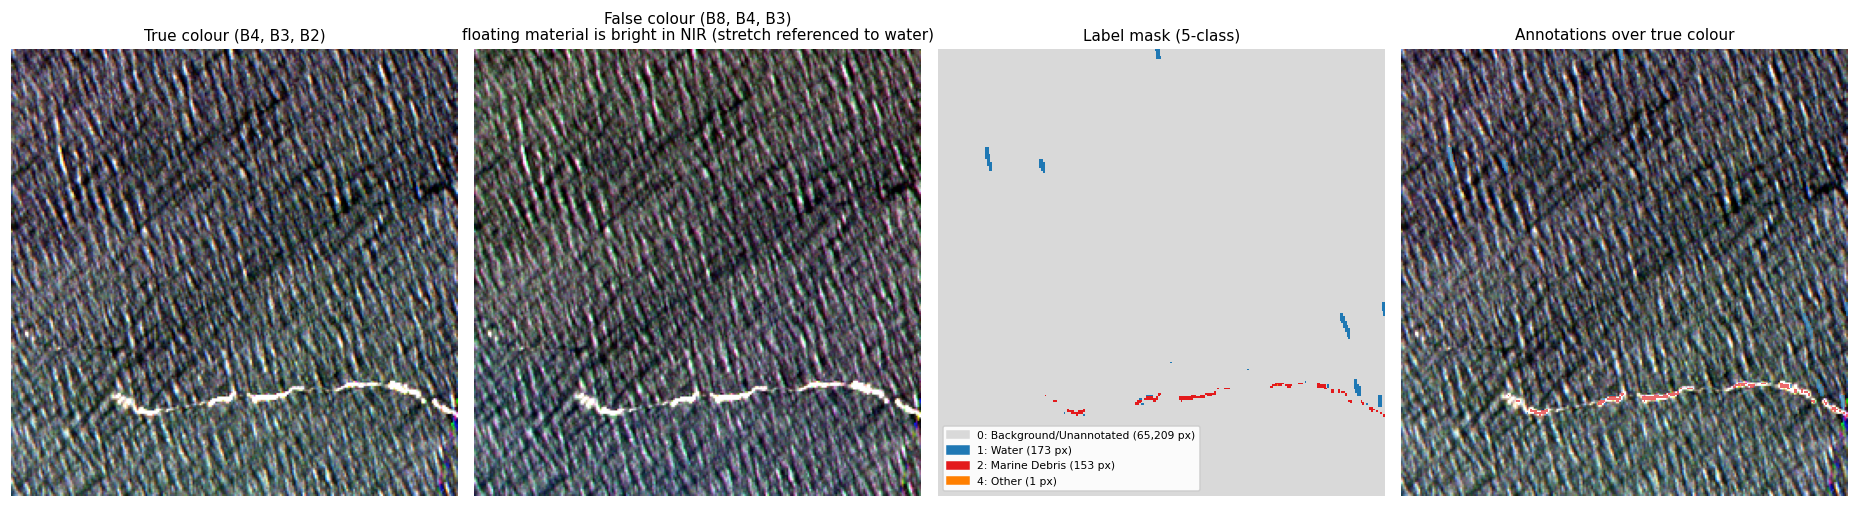

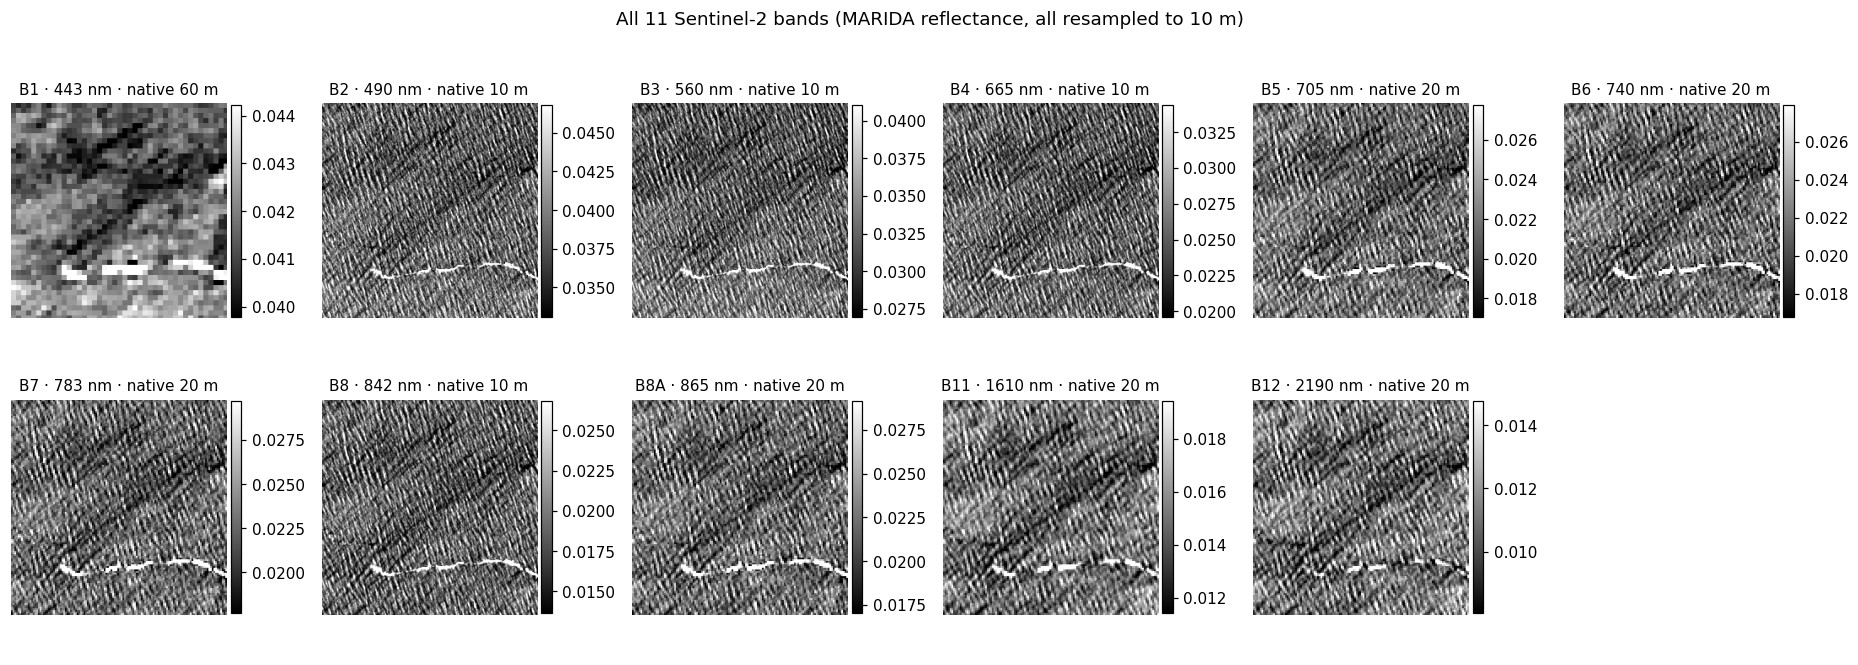

,wavelength_nm,native_res_m,min,mean,median,max
band,,,,,,
B1,443,60,0.0389,0.0418,0.0417,0.0579
B2,490,10,0.0299,0.0388,0.0384,0.1889
B3,560,10,0.0231,0.0328,0.0323,0.2138
B4,665,10,0.0154,0.0256,0.0250,0.2438
B5,705,20,0.0128,0.0218,0.0214,0.1505
B6,740,20,0.0100,0.0217,0.0212,0.1514
B7,783,20,0.0114,0.0229,0.0224,0.1514
B8,842,10,0.0099,0.0190,0.0184,0.2305
B8A,865,20,0.0128,0.0224,0.0219,0.1509


In [8]:
img, mask = show_image(EXAMPLES["Marine Debris"])
show_bands(img)

### Spectral indices and class signatures (the per-pixel classifier features)

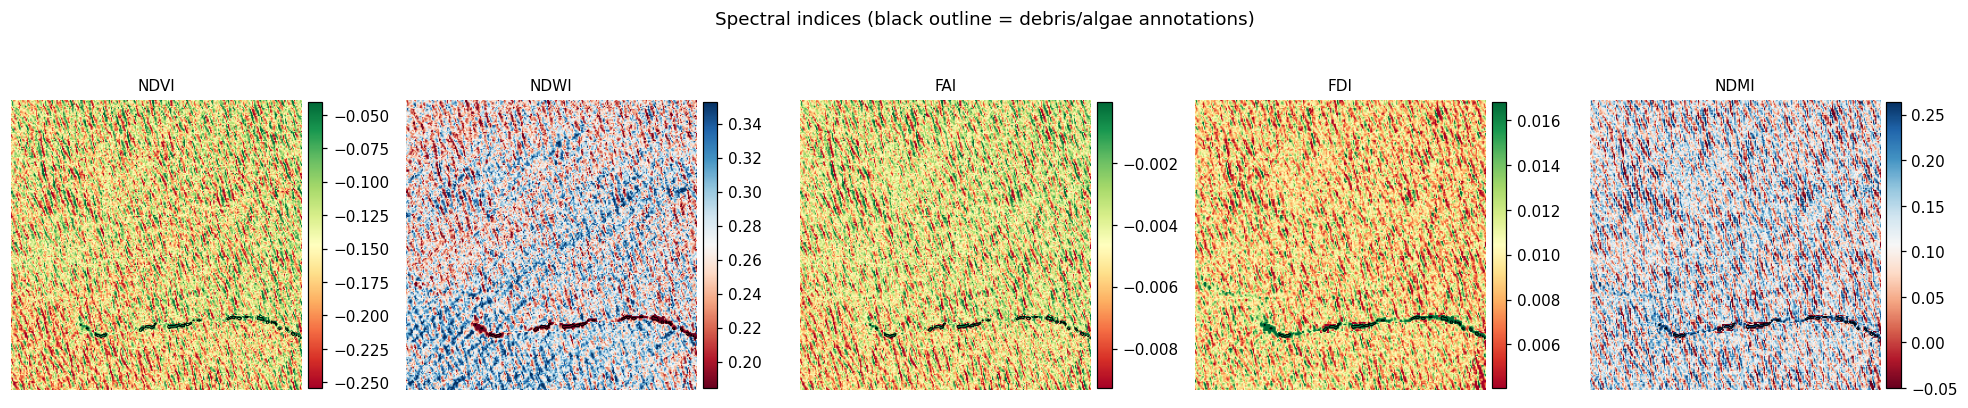

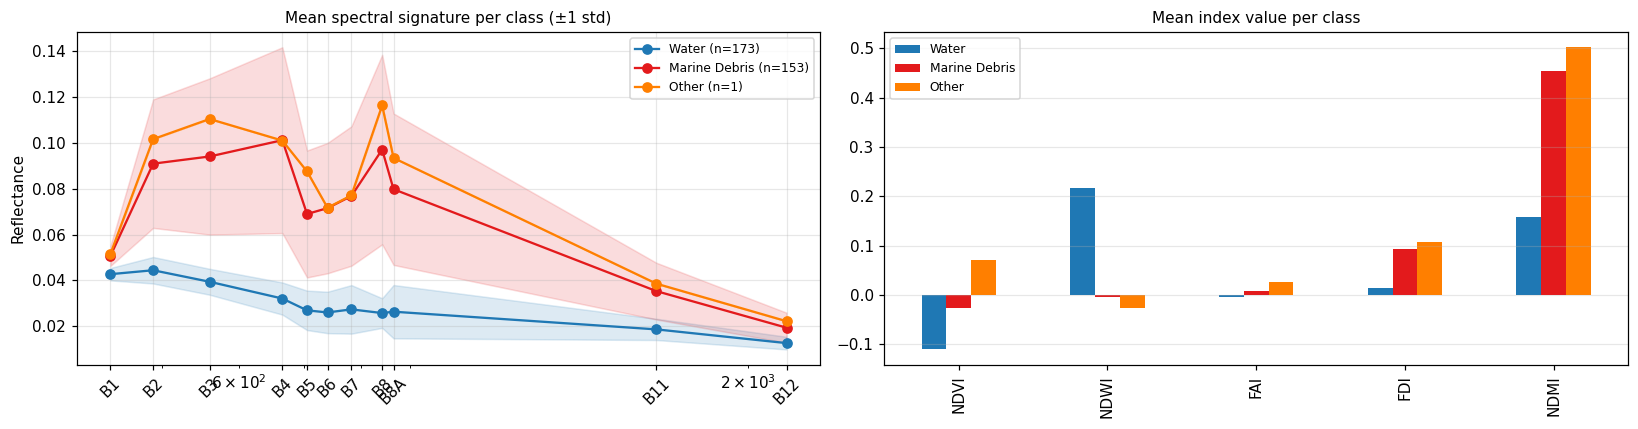

In [9]:
show_indices(img, mask)

### Environmental features attached to this patch

Every pixel in the patch gets these values as extra features. The percentile column places the value within all 1,381 MARIDA patches.

In [10]:
show_env_table(EXAMPLES["Marine Debris"])

**All environmental features for `4-9-16_16PCC_20`** (MUR time used: 2016-09-04T09:00:00Z; chl-a from **8day** composite dated 2016-09-01T00:00:00Z)

### Ocean-colour and SST fields (patch-scale products)

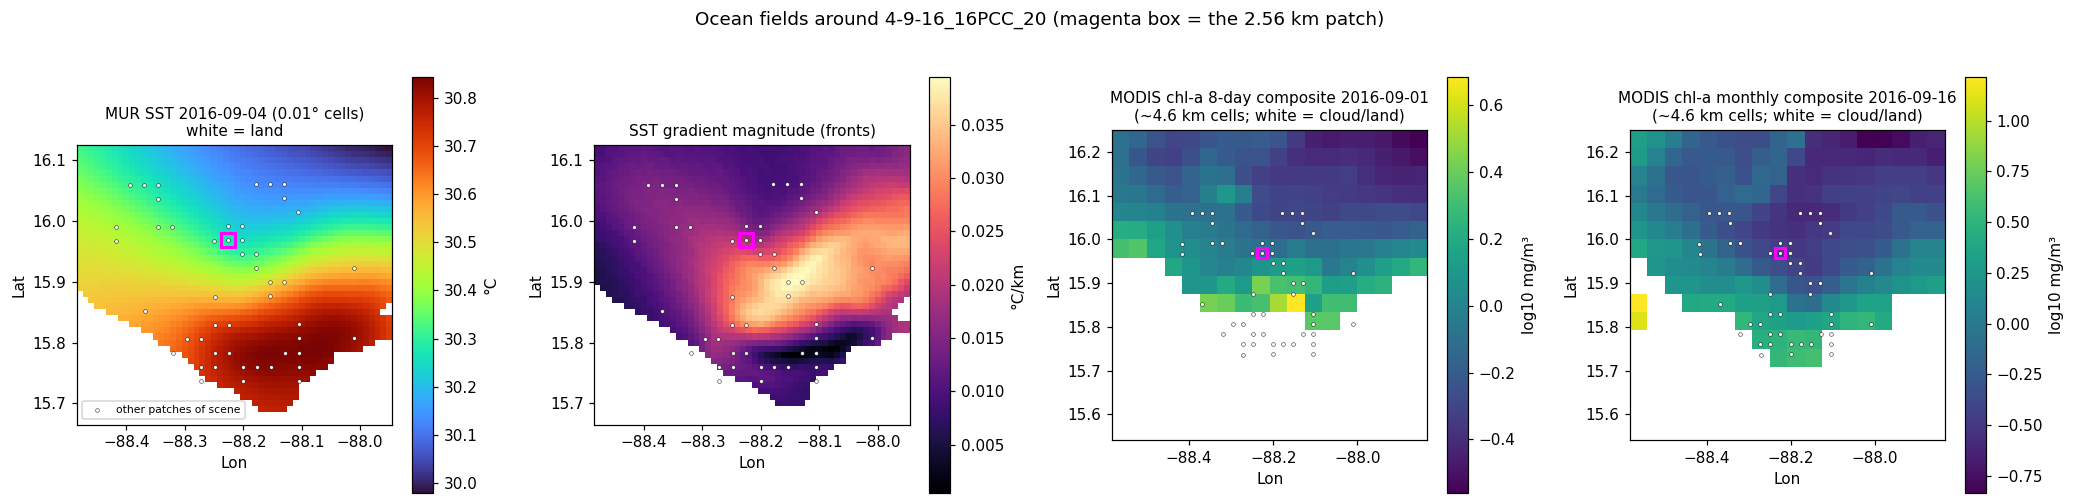

In [11]:
show_ocean_fields(EXAMPLES["Marine Debris"])

### ERA5 fields and the time series behind the antecedent features

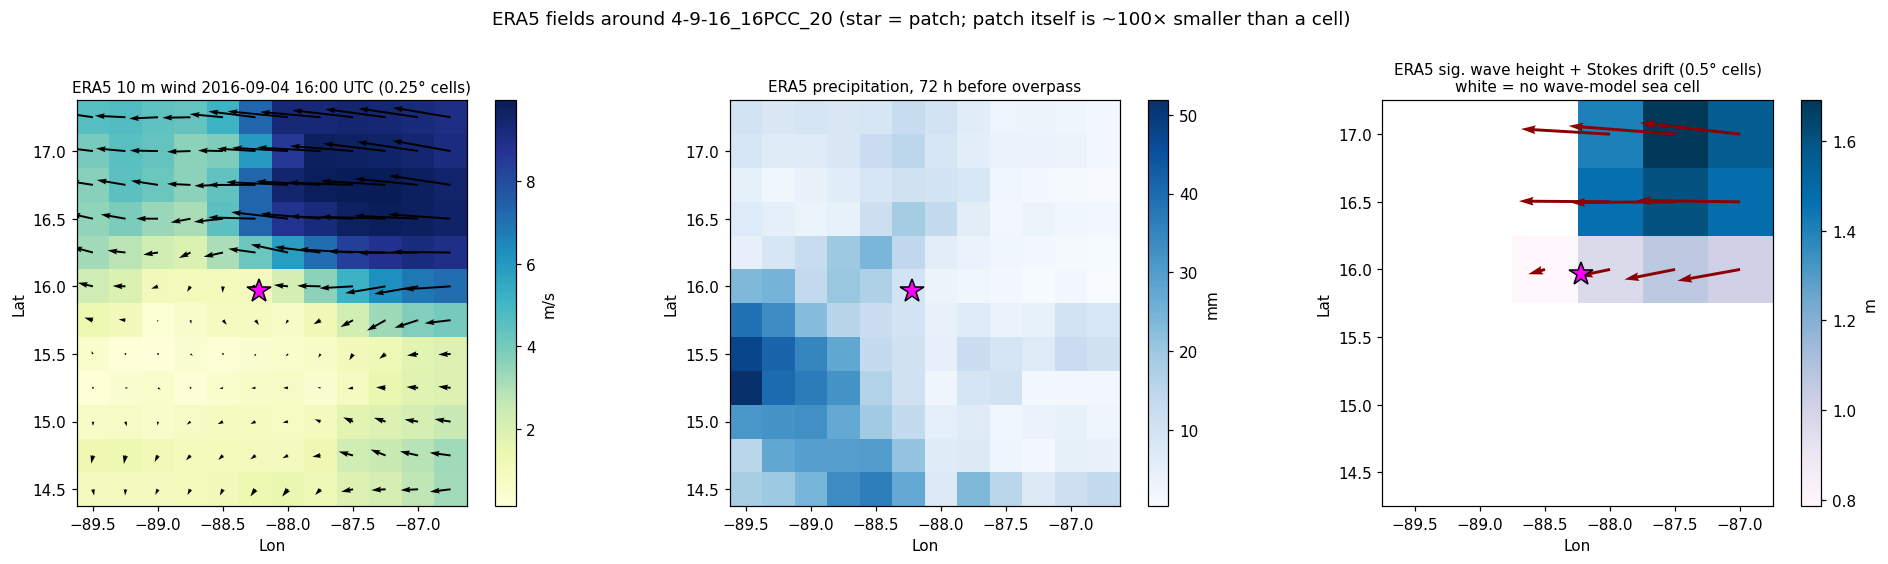

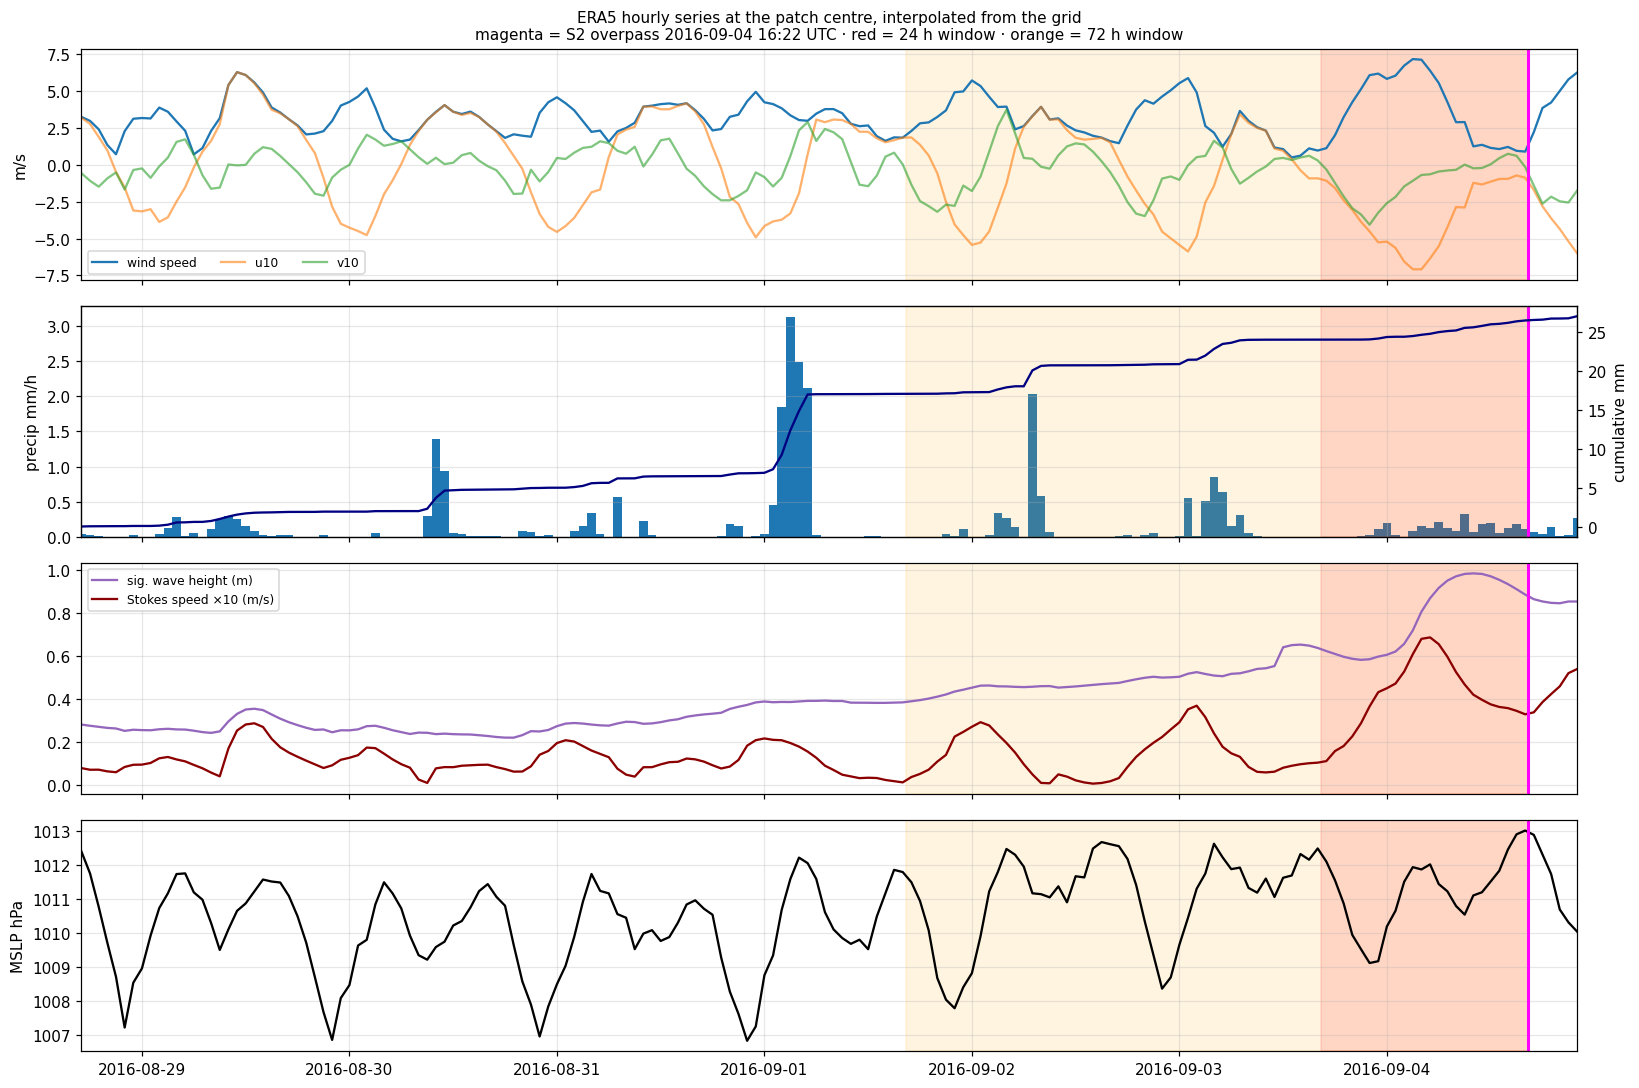

In [12]:
show_era5(EXAMPLES["Marine Debris"])

### How the data resolutions compare to the patch

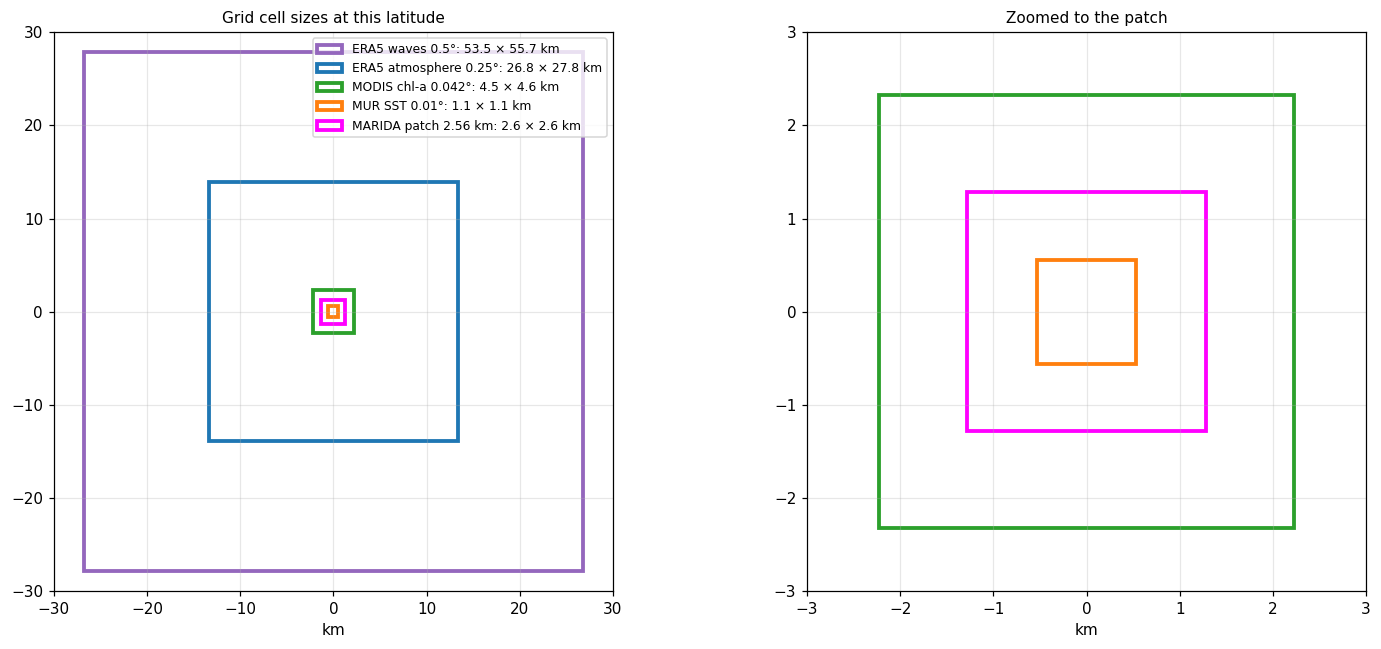

In [13]:
show_resolution(EXAMPLES["Marine Debris"])

## 3. Example patch: Algae/Sargassum

### Image, mask and spectral bands

### Patch `19-9-18_16PCC_33`: tile **16PCC**, acquired **2018-09-19** (estimated overpass 2018-09-19T16:22:23Z), split **val**  
Centre 15.7879°, -88.0987° · EPSG:32616 · footprint 2.56 km × 2.56 km

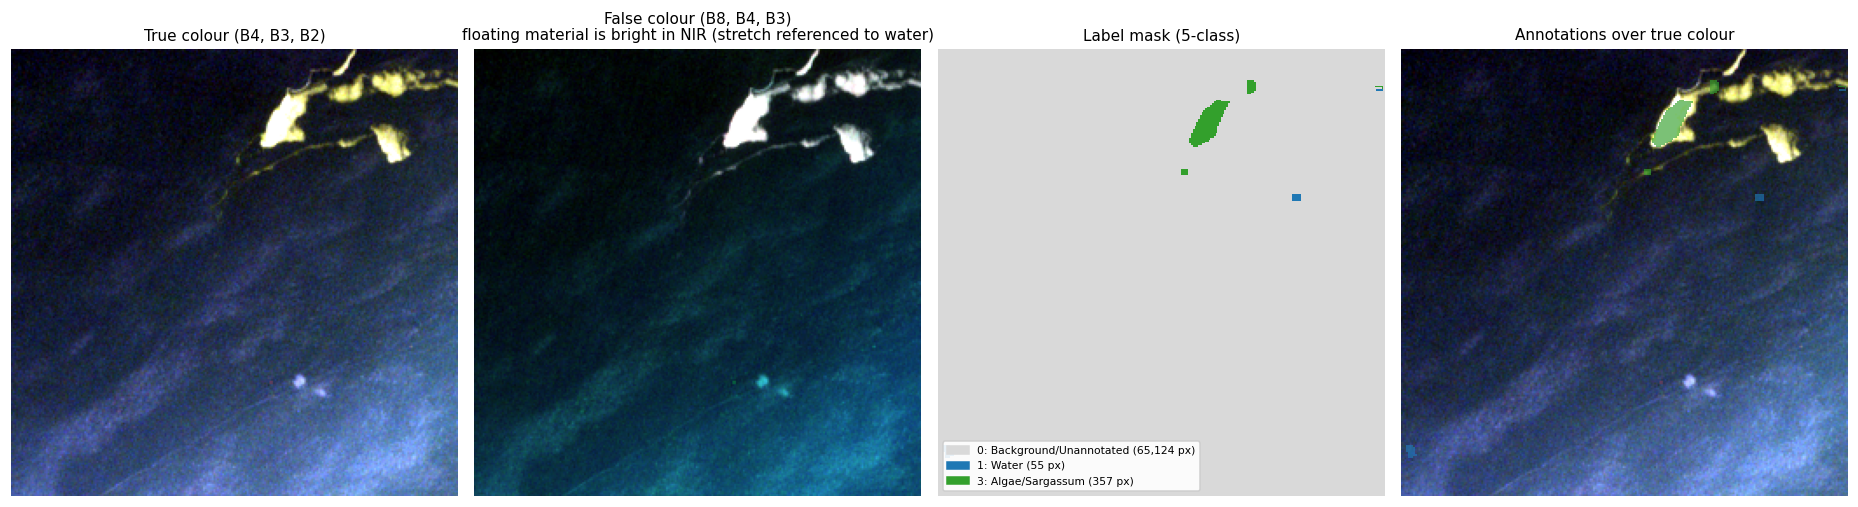

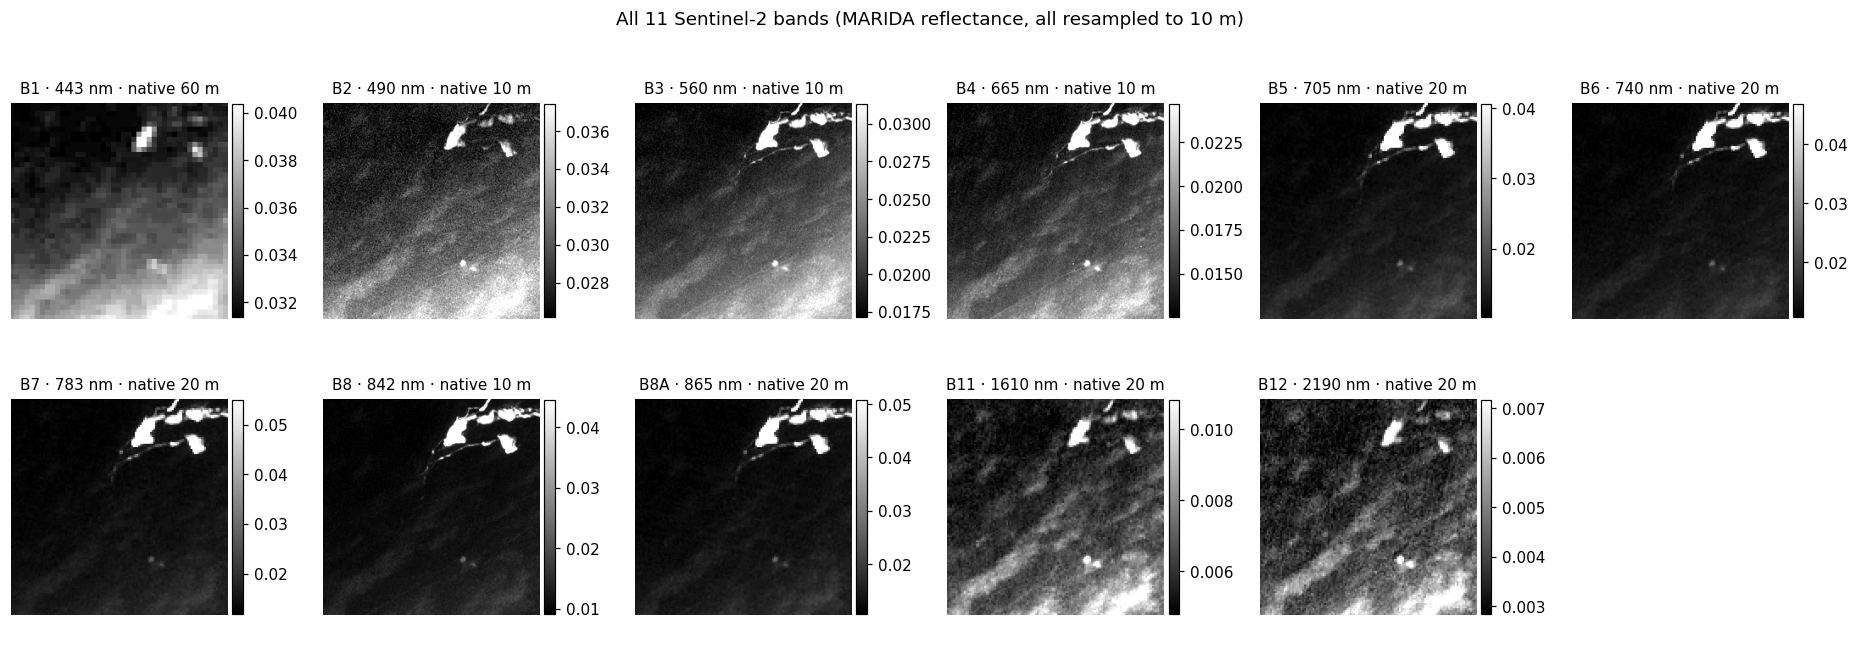

,wavelength_nm,native_res_m,min,mean,median,max
band,,,,,,
B1,443,60,0.0308,0.0343,0.0337,0.0451
B2,490,10,0.0242,0.0301,0.0294,0.0536
B3,560,10,0.0154,0.0218,0.0209,0.0627
B4,665,10,0.0111,0.0162,0.0153,0.0652
B5,705,20,0.0084,0.0144,0.0127,0.1121
B6,740,20,0.0077,0.0151,0.0132,0.1462
B7,783,20,0.0086,0.0170,0.0146,0.1799
B8,842,10,0.0078,0.0136,0.0114,0.1666
B8A,865,20,0.0085,0.0155,0.0132,0.1886


In [14]:
img, mask = show_image(EXAMPLES["Algae/Sargassum"])
show_bands(img)

### Spectral indices and class signatures (the per-pixel classifier features)

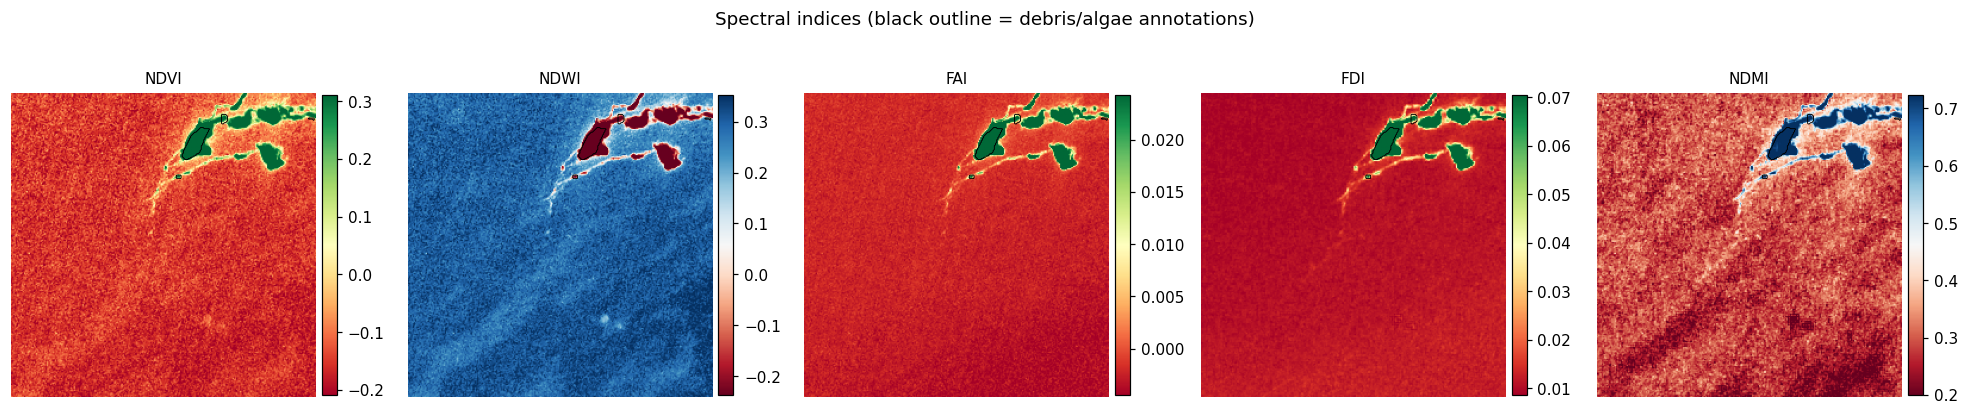

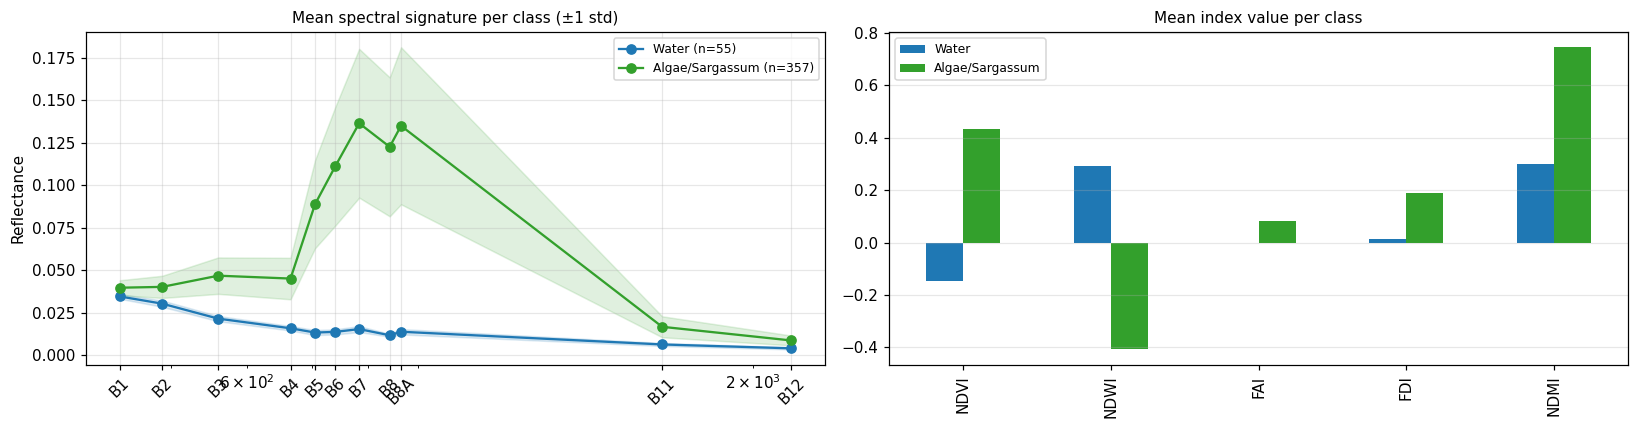

In [15]:
show_indices(img, mask)

### Environmental features attached to this patch

Every pixel in the patch gets these values as extra features. The percentile column places the value within all 1,381 MARIDA patches.

In [16]:
show_env_table(EXAMPLES["Algae/Sargassum"])

**All environmental features for `19-9-18_16PCC_33`** (MUR time used: 2018-09-19T09:00:00Z; chl-a from **8day** composite dated 2018-09-18T00:00:00Z)

### Ocean-colour and SST fields (patch-scale products)

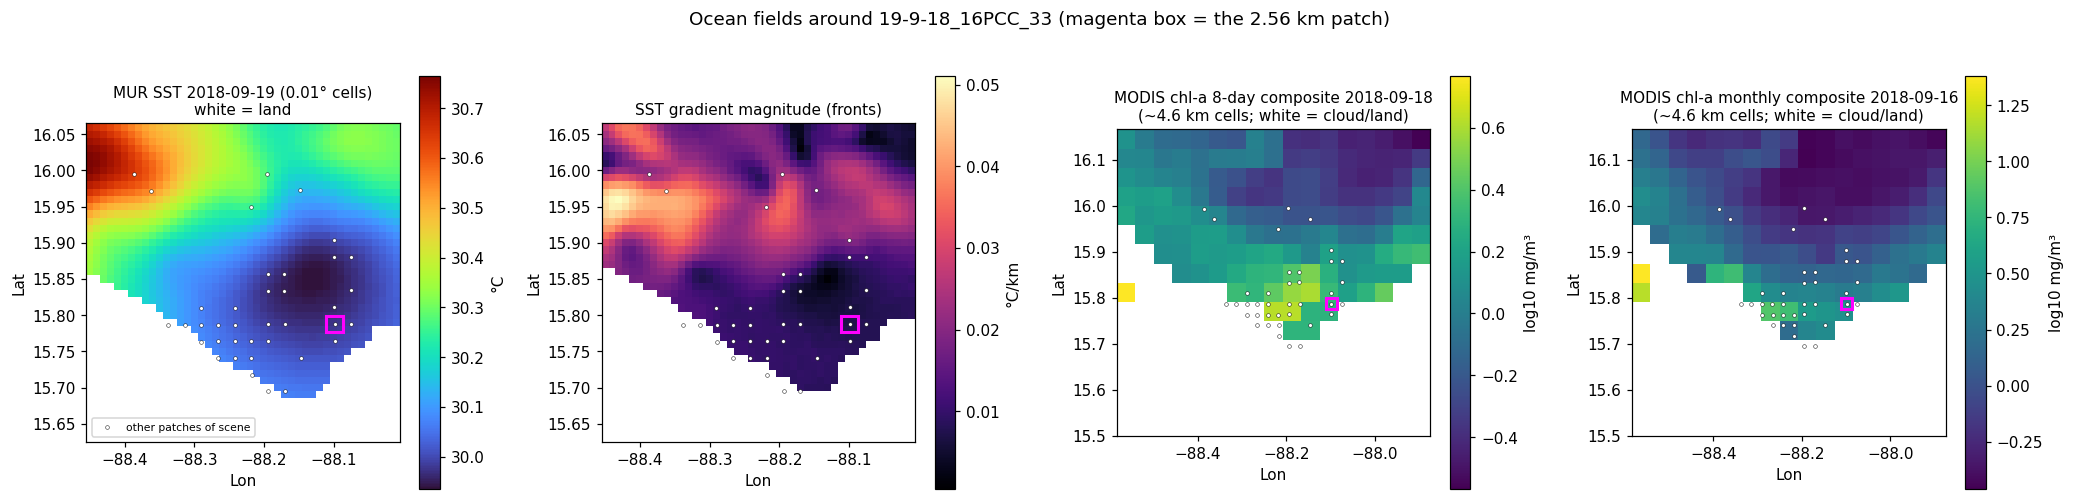

In [17]:
show_ocean_fields(EXAMPLES["Algae/Sargassum"])

### ERA5 fields and the time series behind the antecedent features

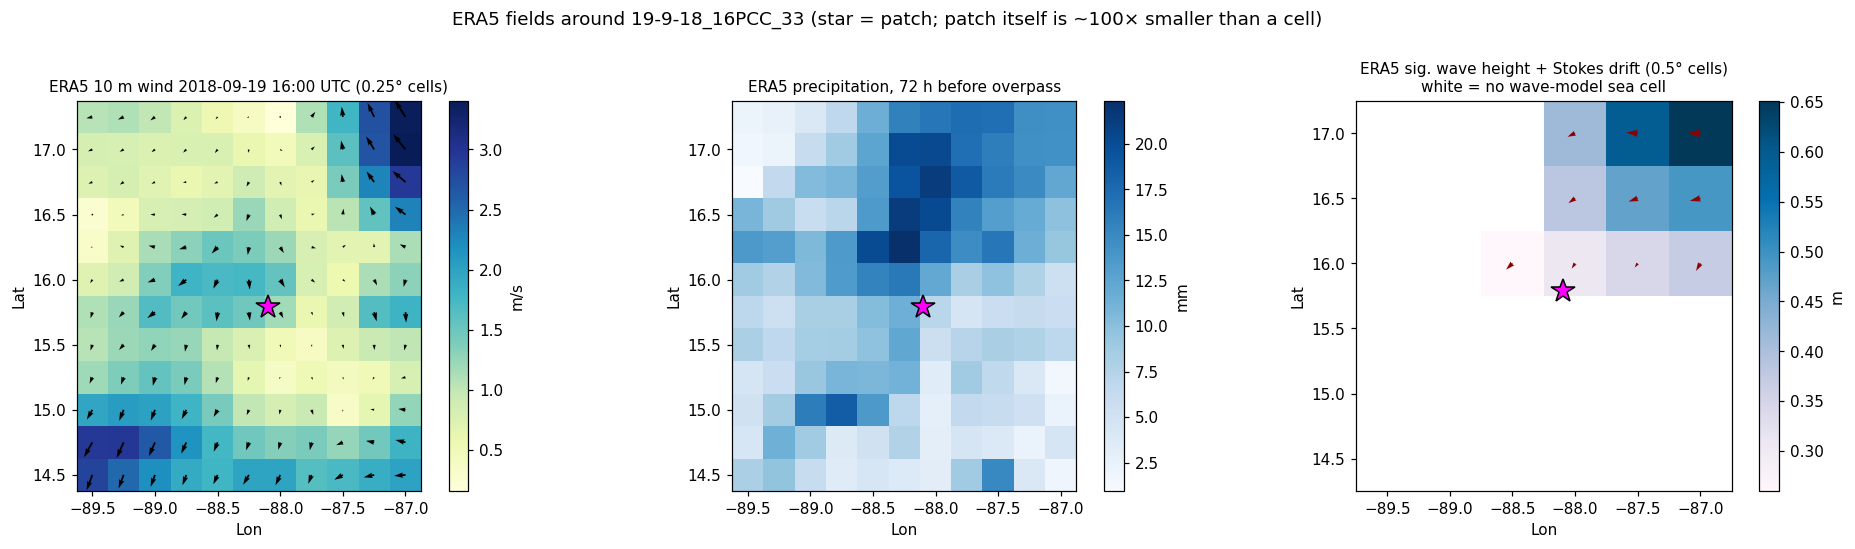

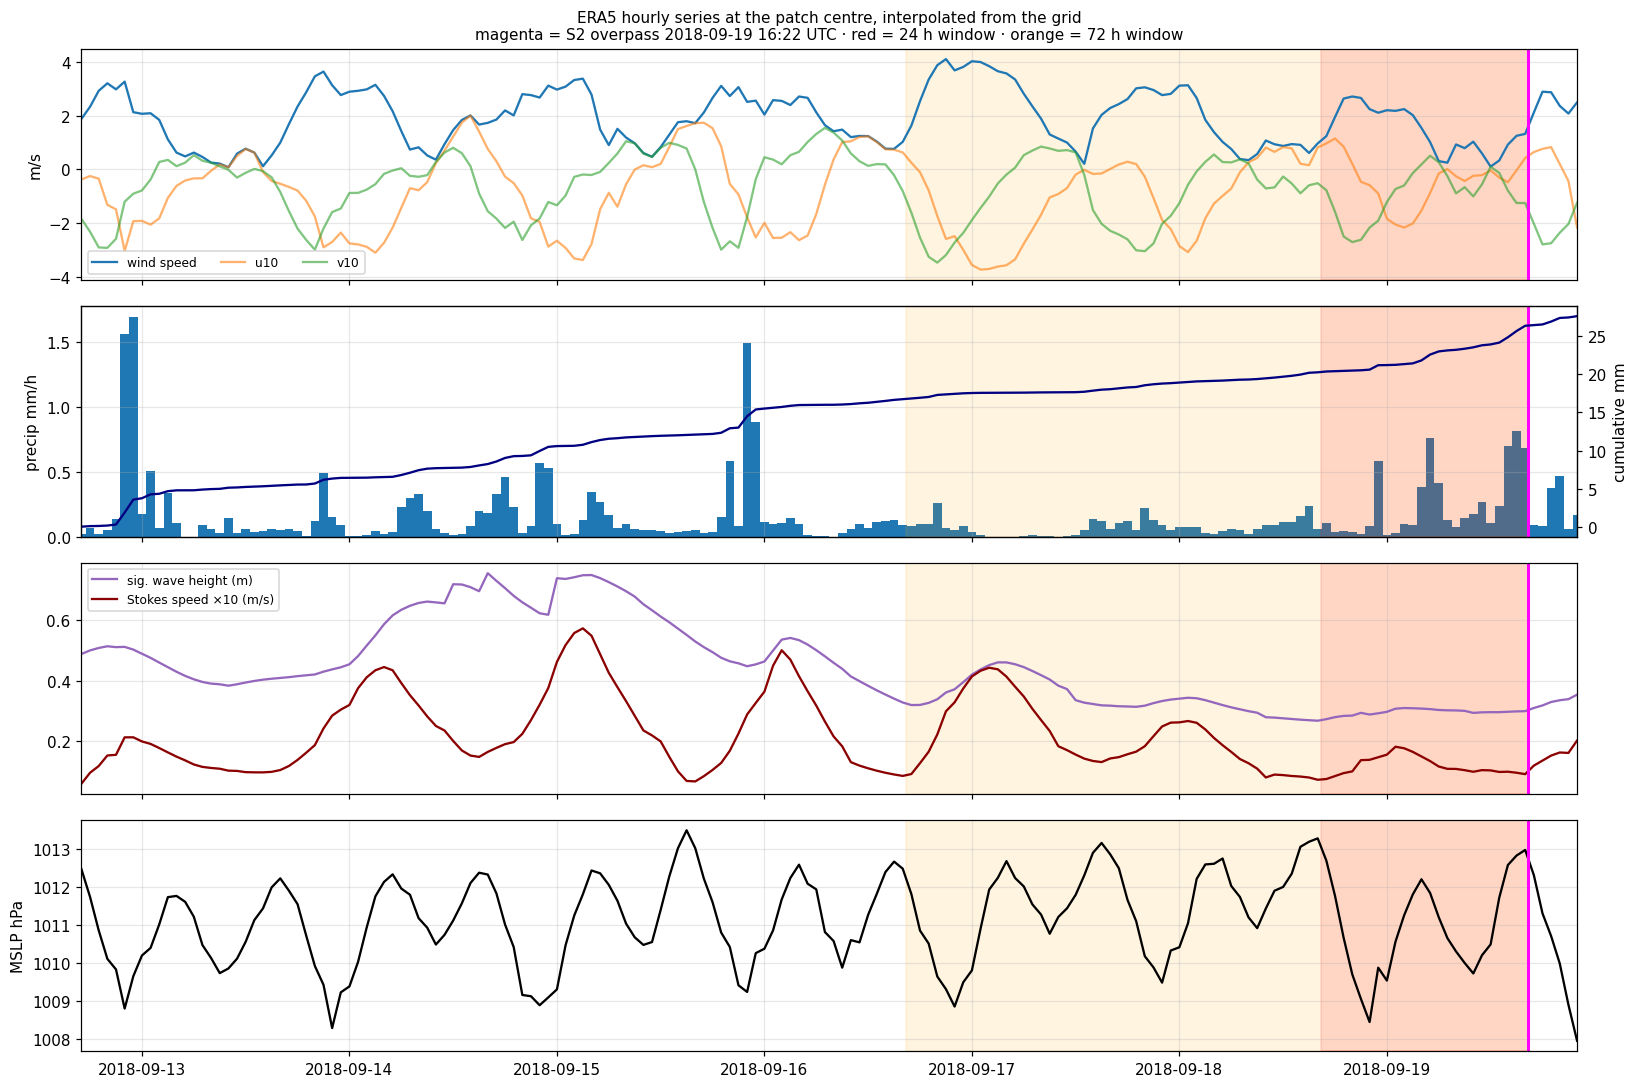

In [18]:
show_era5(EXAMPLES["Algae/Sargassum"])

## 4. Side-by-side comparison of the two examples

In [19]:
cmp = ENV.loc[list(EXAMPLES.values()), list(FEATURE_INFO)].T
cmp.columns = [f"{k}\n{v}" for k, v in EXAMPLES.items()]
cmp.insert(0, "unit", [FEATURE_INFO[c][1] for c in cmp.index])
cmp["MARIDA median"] = ENV[list(FEATURE_INFO)].median()
display(cmp.style.format("{:.4g}", subset=cmp.columns[1:], na_rep="n/a"))

,unit,Marine Debris 4-9-16_16PCC_20,Algae/Sargassum 19-9-18_16PCC_33,MARIDA median
mur_sst_c,°C,30.27,29.97,28.94
mur_sst_grad_c_per_km,°C/km,0.019,0.00722,0.01749
modis_log10_chla,log10 mg/m³,-0.03882,0.3036,0.06688
era5_u10,m/s,-1.196,0.5071,-0.7148
era5_v10,m/s,-0.6335,-1.537,-0.5573
era5_wind_speed,m/s,1.353,1.619,1.884
era5_wind_speed_mean_24h,m/s,3.776,1.442,2.402
era5_wind_speed_mean_72h,m/s,3.296,1.924,2.478
era5_wind_speed_max_72h,m/s,7.162,4.108,5.121
era5_u10_mean_72h,m/s,-1.474,-0.9182,-0.7546


## 5. Environmental features across the whole MARIDA dataset

Distributions over all 1,381 patches, with the two examples marked. The env values mostly vary **between scenes**: there are 63 scenes, and patches of one scene share very similar values. Keep this in mind when interpreting model gains.

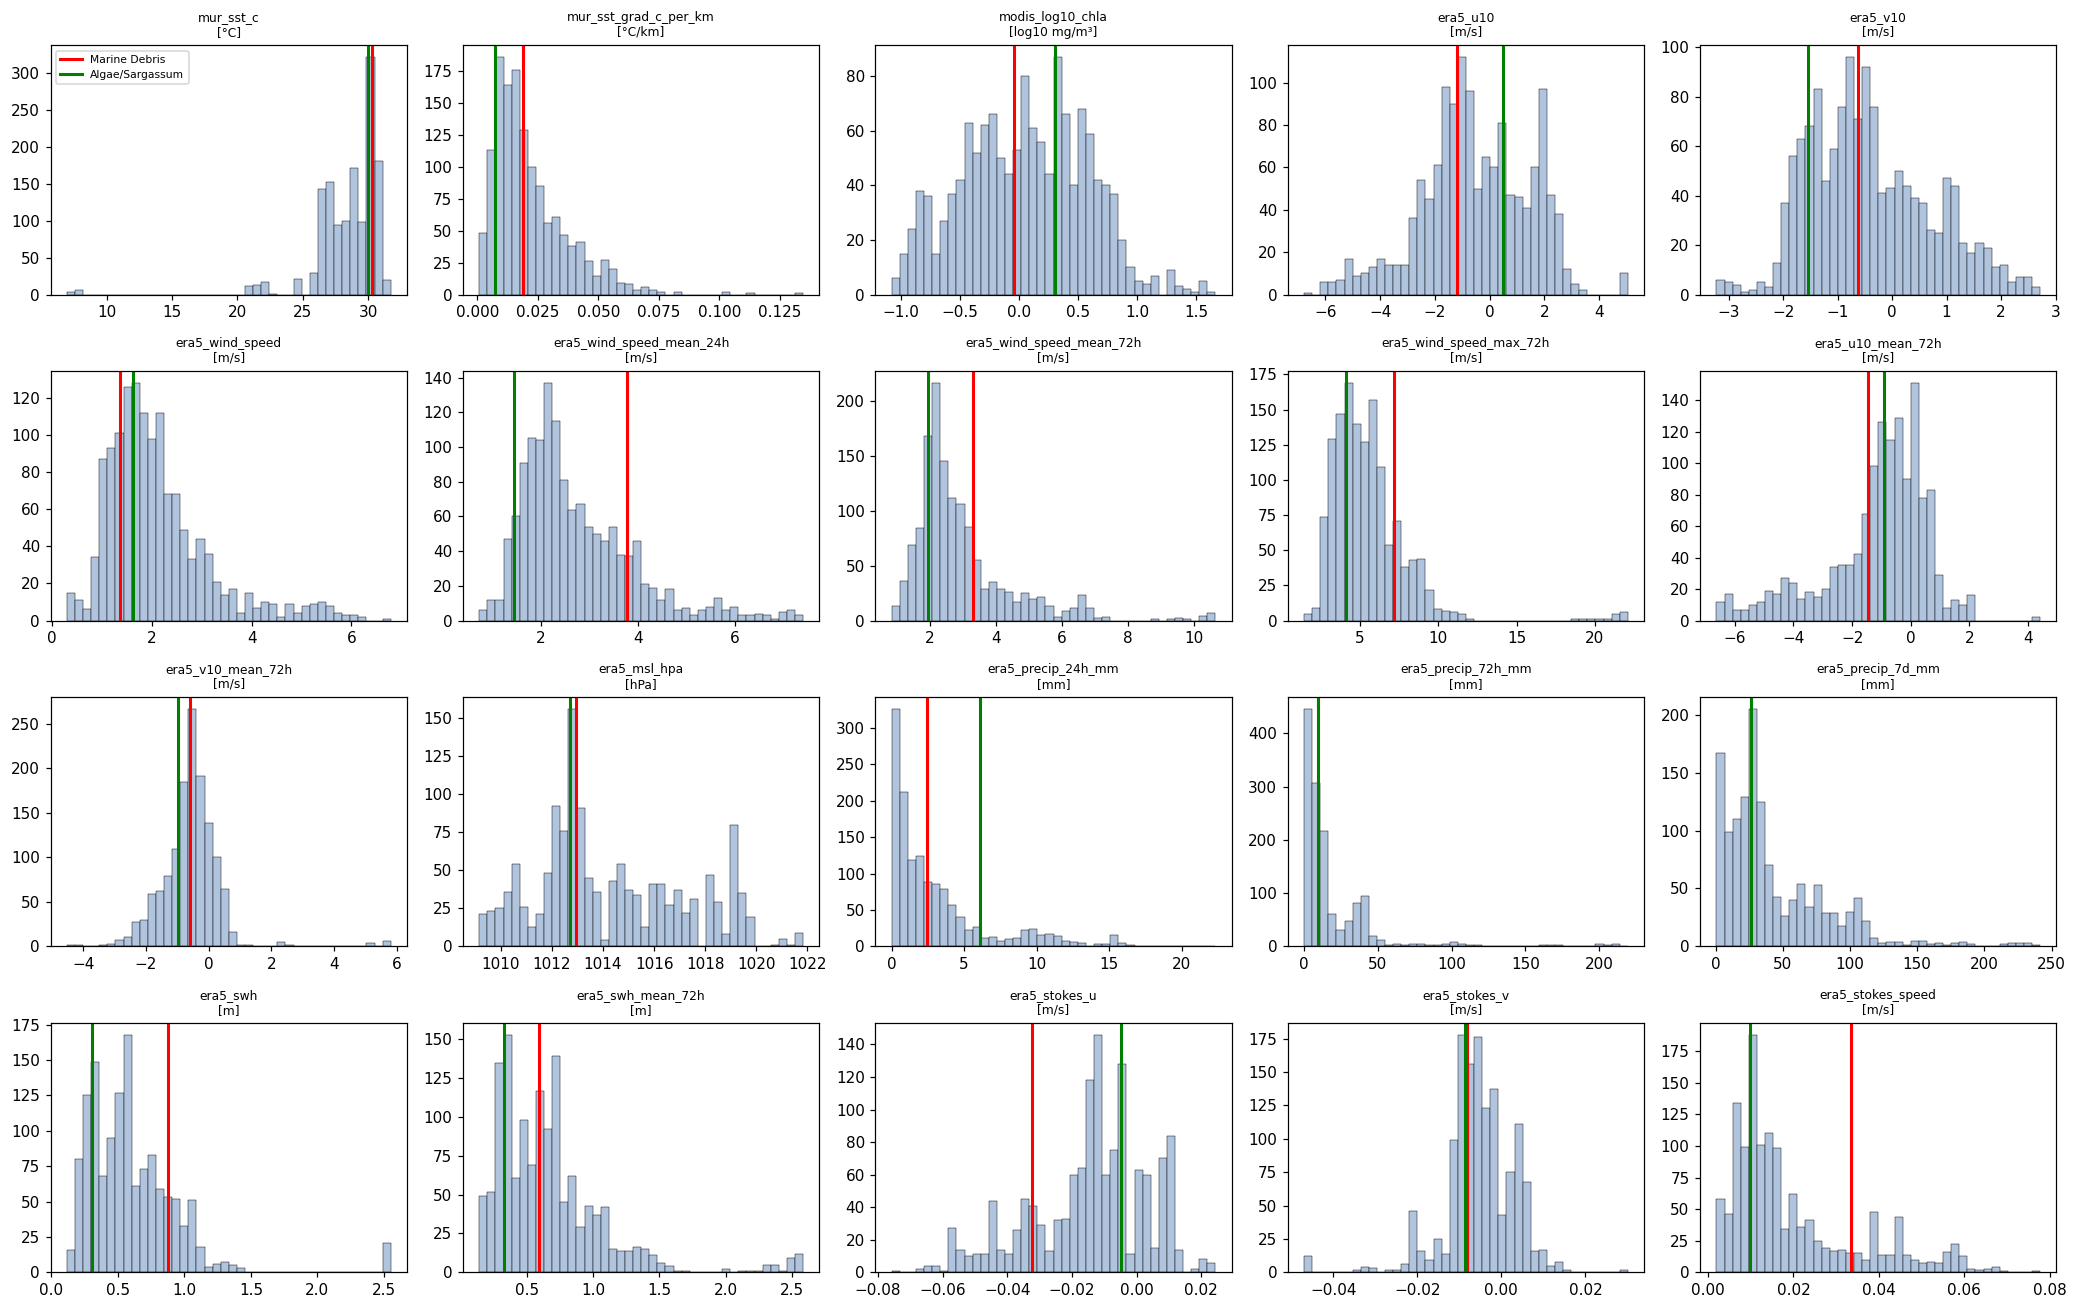

,mur_sst_c,mur_sst_grad_c_per_km,modis_log10_chla,era5_u10,era5_v10,era5_wind_speed,era5_wind_speed_mean_24h,era5_wind_speed_mean_72h,era5_wind_speed_max_72h,era5_u10_mean_72h,era5_v10_mean_72h,era5_msl_hpa,era5_precip_24h_mm,era5_precip_72h_mm,era5_precip_7d_mm,era5_swh,era5_swh_mean_72h,era5_stokes_u,era5_stokes_v,era5_stokes_speed
patches with value,1381,1371,1377,1381,1381,1381,1381,1381,1381,1381,1381,1381,1381,1381,1381,1357,1357,1357,1357,1357
distinct values,1381,1371,1341,1381,1381,1381,1381,1381,1381,1381,1381,1381,1377,1377,1381,1250,1139,1246,1246,1246
distinct per-scene means,63,63,62,63,63,63,63,63,63,63,63,63,63,63,63,61,61,61,61,61


In [20]:
cols = list(FEATURE_INFO)
fig, axes = plt.subplots(4, 5, figsize=(19, 12))
for a, c in zip(axes.flat, cols):
    a.hist(ENV[c].dropna(), bins=40, color="lightsteelblue", edgecolor="k", lw=0.3)
    for (name, pid), col in zip(EXAMPLES.items(), ["red", "green"]):
        if pd.notna(ENV.loc[pid, c]): a.axvline(ENV.loc[pid, c], color=col, lw=2, label=name)
    a.set_title(f"{c}\n[{FEATURE_INFO[c][1]}]", fontsize=8)
axes.flat[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

coverage = pd.DataFrame({"patches with value": ENV[cols].notna().sum(),
                         "distinct values": ENV[cols].nunique(),
                         "distinct per-scene means": ENV.groupby("scene")[cols].mean().nunique()})
display(coverage.T)

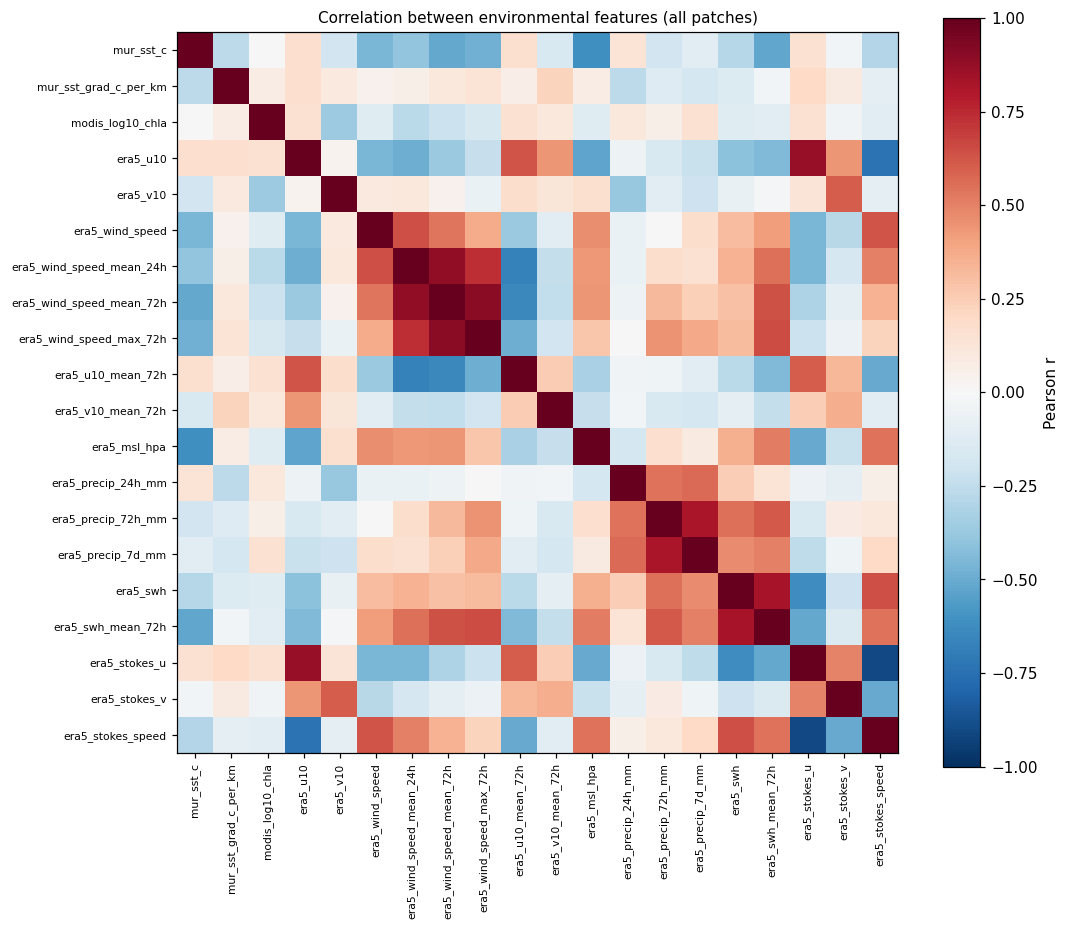

In [21]:
corr = ENV[cols].corr()
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=90, fontsize=7)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=7)
plt.colorbar(im, ax=ax, label="Pearson r"); ax.set_title("Correlation between environmental features (all patches)")
plt.tight_layout(); plt.show()

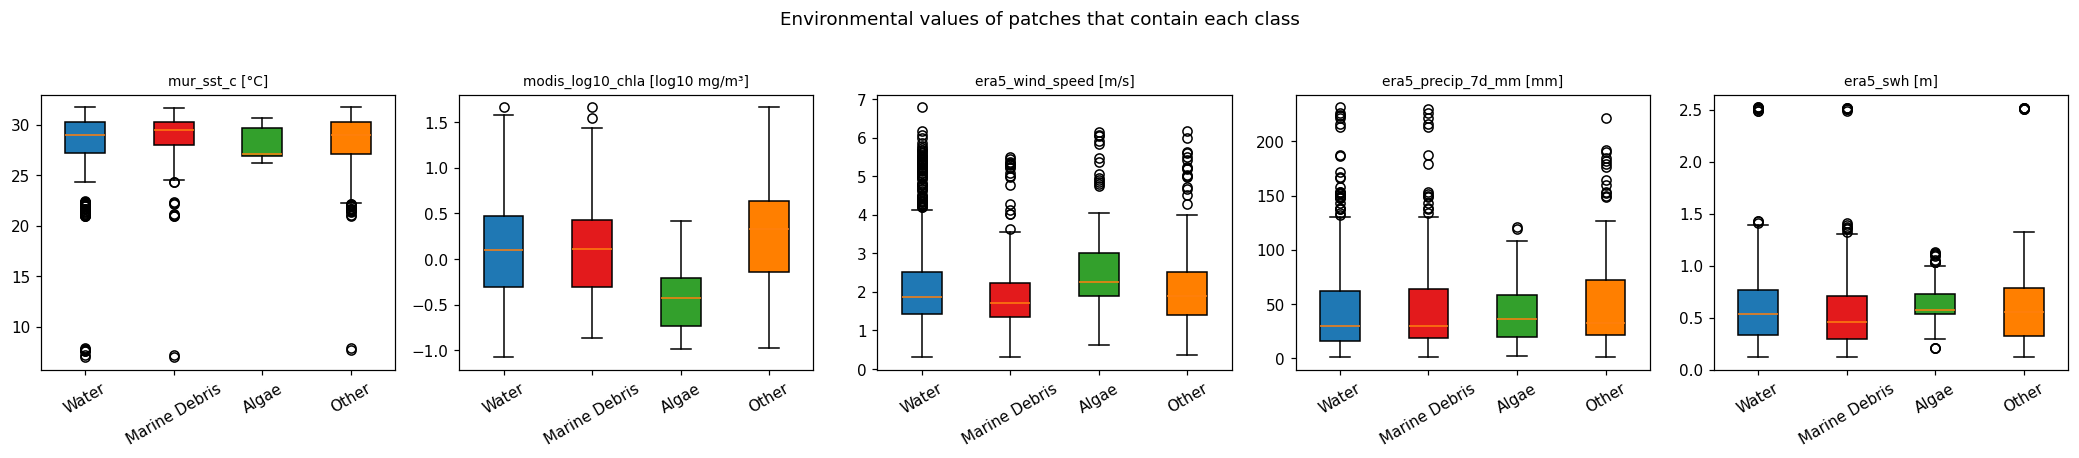

{'Water': 1158, 'Marine Debris': 373, 'Algae/Sargassum': 114, 'Other': 309} patches per class


In [22]:
# Per-class view: env values of patches containing each annotated class
import tifffile
present = {c: [] for c in range(1, 5)}
for pid, r in ENV.iterrows():
    m = tifffile.imread(os.path.join(MARIDA, "patches", f"S2_{r.scene}", f"S2_{pid}_cl.tif"))
    for c in range(1, 5):
        if (m == c).any(): present[c].append(pid)
show = ["mur_sst_c", "modis_log10_chla", "era5_wind_speed", "era5_precip_7d_mm", "era5_swh"]
fig, axes = plt.subplots(1, len(show), figsize=(19, 4))
for a, c in zip(axes, show):
    data = [ENV.loc[present[k], c].dropna() for k in range(1, 5)]
    bp = a.boxplot(data, patch_artist=True)
    a.set_xticks(range(1, 5)); a.set_xticklabels([CLASS_NAMES[k].split("/")[0] for k in range(1, 5)])
    for b, k in zip(bp["boxes"], range(1, 5)): b.set_facecolor(CLASS_COLORS[k])
    a.set_title(f"{c} [{FEATURE_INFO[c][1]}]", fontsize=9); a.tick_params(axis="x", rotation=30)
plt.suptitle("Environmental values of patches that contain each class", y=1.03)
plt.tight_layout(); plt.show()
print({CLASS_NAMES[k]: len(v) for k, v in present.items()}, "patches per class")